# 01. Data audit and EDA

**Question.** When a visitor is about to leave the site, should the marketing system show them a discount pop-up?
Pop-ups can go to at most 10% of sessions, so we need to rank sessions by how close they are to buying.

This notebook answers the data questions from the course workflow. What is one row? When is each column written?
What is missing and why? Which split matches how the model will be used? It also starts the investigation of the
one column that looks too good, `PageValues`.

Everything here reads the frozen raw file and the cleaning code in `src/data.py`, so the notebook and the
training script can never disagree.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src import config, data, evaluate, features

## 1. Load the frozen file and check its hash

The file was downloaded once from the UCI repository on 2026-11-26. `load_raw` stops if the MD5 does not match the
frozen copy, because a changed file would make every number in the report out of date.

In [2]:
raw = data.load_raw()
print("MD5:", data.file_md5(config.RAW_FILE))
print("shape:", raw.shape)
raw.head()

MD5: cc6ec1db03b4f10f8de52c56ff48b085
shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
raw.dtypes.to_frame("dtype").T

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
dtype,int64,float64,int64,float64,int64,float64,float64,float64,float64,float64,str,int64,int64,int64,int64,str,bool,bool


**One row is one browsing session.** The dataset authors say each session belongs to a different user over a one-year
period. There is no user ID and no date, only a month.

## 2. Missing values, duplicates and odd spellings

In [4]:
print("missing values per column:", int(raw.isna().sum().sum()))
print("exact duplicate rows:", int(raw.duplicated().sum()))
print()
print(raw["Month"].value_counts().to_string())

missing values per column: 0
exact duplicate rows: 125

Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184


* **No missing values** in this version of the file, so there is nothing to fill in and no missingness pattern to
  explain. The page counters are zero when a page type was not visited, which is a real zero, not a gap.
* **125 exact duplicates.** The next cell shows what they look like.

In [5]:
dups = raw[raw.duplicated(keep=False)]
dups[["Administrative", "Informational", "ProductRelated", "ProductRelated_Duration",
      "BounceRates", "ExitRates", "PageValues", "Revenue"]].describe().loc[["mean", "min", "max"]]

,Administrative,Informational,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
mean,0.0,0.0,1.059701,0.0,0.2,0.2,0.0
min,0.0,0.0,1.000000,0.0,0.2,0.2,0.0
max,0.0,0.0,2.000000,0.0,0.2,0.2,0.0


The duplicates are all one- or two-page sessions with the maximum bounce and exit rate (0.2) and no purchase. They are
most likely different visitors who bounced in the same way. They are still dropped before the split, because the same
row on both sides of a train/test split makes the test look easier than it is.

**Month spellings.** June is written `June` while every other month has three letters, and January and April never
appear. `src/data.clean` renames `June` to `Jun`. The missing months matter for deployment: the model has never seen a
January or April session, and the API accepts them but treats them as unknown.

In [6]:
df = data.clean(raw)
print(df.shape)
print("buy rate:", round(df[config.TARGET].mean(), 4))
print("'nobody buys' accuracy:", round(1 - df[config.TARGET].mean(), 4))

dropped 125 duplicate rows, 12205 left
(12205, 18)
buy rate: 0.1563
'nobody buys' accuracy: 0.8437


**Class balance.** About 15.6% of sessions end in a purchase. A model that says "nobody buys" is already 84% accurate,
which is why accuracy is never used as the headline in this project. PR-AUC and precision at the 10% pop-up limit are.

## 3. Point-in-time audit of every column

The decision point is the moment of exit intent. A column can only be a feature if it is known at that moment.

| Column | When is it written? | Use it? |
|---|---|---|
| `Administrative`, `Informational`, `ProductRelated` | Counted as the visitor clicks. Known so far at exit intent | Yes |
| `*_Duration` | Same, seconds on each page type so far | Yes |
| `BounceRates`, `ExitRates` | GA rates of the pages visited, computed from **other** visitors' past traffic | Yes |
| `PageValues` | GA value of the pages visited. A page earns value when a **transaction follows it in the same session** | **Suspect** |
| `SpecialDay` | Calendar, known in advance | Yes |
| `Month`, `Weekend` | Calendar | Yes |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Known when the session starts | Yes, as categories |
| `VisitorType` | Known when the session starts | Yes |
| `Revenue` | End of the session | Target |

**A limitation that applies to every counter.** The file holds whole-session totals. In real use, the model would see
the counts *up to* the exit-intent moment, which are a little smaller. Sessions that end in a purchase also include the
cart and checkout clicks. So the offline scores here are a bit optimistic for every model, including the baselines.
The dataset cannot fix this, and the report says so.

## 4. Distributions and outliers

In [7]:
num_cols = config.COUNT_FEATURES + config.DURATION_FEATURES + ["BounceRates", "ExitRates", "PageValues"]
summary = df[num_cols].describe(percentiles=[0.5, 0.9, 0.99]).T[["mean", "50%", "90%", "99%", "max"]]
summary["skew"] = df[num_cols].skew()
summary.round(2)

,mean,50%,90%,99%,max,skew
Administrative,2.34,1.00,7.00,14.00,27.00,1.95
Informational,0.51,0.00,2.00,6.00,24.00,4.01
ProductRelated,32.05,18.00,74.00,221.00,705.00,4.33
Administrative_Duration,81.65,9.00,227.00,838.70,3398.75,5.59
Informational_Duration,34.83,0.00,73.90,722.38,2549.38,7.54
ProductRelated_Duration,1206.98,608.94,2904.46,8704.27,63973.52,7.25
BounceRates,0.02,0.00,0.05,0.20,0.20,3.16
ExitRates,0.04,0.02,0.10,0.20,0.20,2.23
PageValues,5.95,0.00,19.11,86.11,361.76,6.35


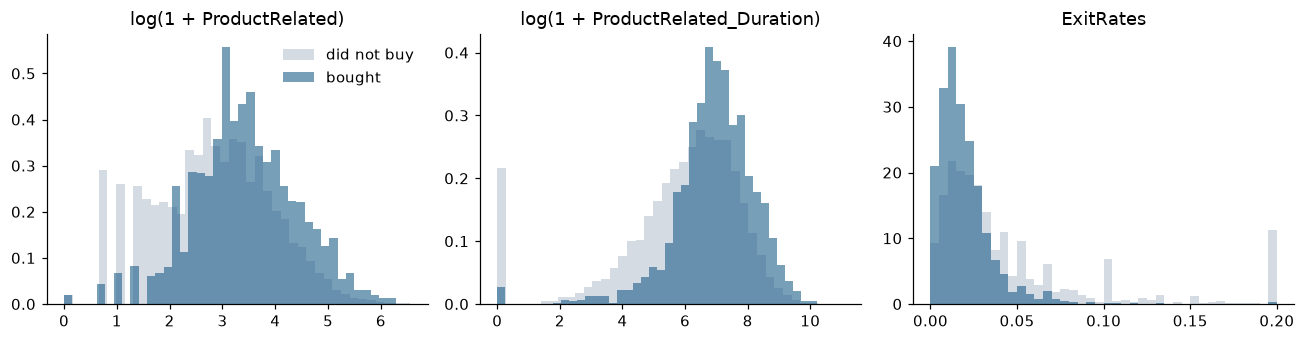

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col in zip(axes, ["ProductRelated", "ProductRelated_Duration", "ExitRates"]):
    for label, part in df.groupby(config.TARGET):
        values = np.log1p(part[col]) if col != "ExitRates" else part[col]
        ax.hist(values, bins=40, alpha=0.6, density=True, label="bought" if label else "did not buy",
                color="#1d5f8a" if label else "#b9c3cf")
    ax.set_title(col if col == "ExitRates" else f"log(1 + {col})")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

**What this shows.**

* Counts and durations have long right tails (skew between 2 and 7). One session spent almost 18 hours on product pages.
  These are not errors, so they are kept, and the pipeline log-transforms them. The log matters for logistic regression.
  Trees do not care.
* Buyers look at more product pages and spend longer on them, but the two groups overlap a lot. No single counter
  separates them cleanly.
* `ExitRates` is the clearest single signal among the safe columns. Sessions sitting on pages people usually leave
  from rarely buy. Every one of the 585 sessions with the maximum exit rate of 0.2 is a near-certain non-buyer.

In [9]:
def buy_rate(col):
    return df.groupby(col)[config.TARGET].agg(buy_rate="mean", sessions="size").round(3)

display(buy_rate("VisitorType"))
display(buy_rate("Weekend"))
display(buy_rate("Month").reindex(config.MONTHS))

,buy_rate,sessions
VisitorType,,
New_Visitor,0.249,1693
Other,0.198,81
Returning_Visitor,0.141,10431


,buy_rate,sessions
Weekend,,
0,0.151,9346
1,0.175,2859


,buy_rate,sessions
Month,,
Feb,0.017,181
Mar,0.103,1860
May,0.110,3329
Jun,0.102,285
Jul,0.153,432
Aug,0.176,433
Sep,0.192,448
Oct,0.209,549
Nov,0.255,2982


* **New visitors buy more often (25%) than returning visitors (14%).** That surprised me. A likely reason is that
  returning visitors include people who come back many times just to browse.
* **Season matters a lot.** November has a 25% buy rate and holds about a quarter of all sessions, while February is
  under 2%. A model that uses `Month` will give out far more pop-ups in November. Notebook 03 checks what that means for
  the 10% limit.
* Weekends are only slightly better than weekdays.

In [10]:
for col in config.CODE_FEATURES:
    counts = df[col].value_counts()
    print(f"{col:17s} {counts.size:2d} codes, the 3 most common cover {counts.head(3).sum() / len(df):.0%}, "
          f"rarest has {counts.min()} sessions")

OperatingSystems   8 codes, the 3 most common cover 95%, rarest has 6 sessions
Browser           13 codes, the 3 most common cover 90%, rarest has 1 sessions
Region             9 codes, the 3 most common cover 68%, rarest has 318 sessions
TrafficType       20 codes, the 3 most common cover 68%, rarest has 1 sessions


`OperatingSystems`, `Browser`, `Region` and `TrafficType` are integer codes, but browser 8 is not "more" than browser 2.
They are one-hot encoded, and codes with fewer than 30 training sessions are pooled into one "infrequent" column so the
model does not learn from a handful of rows.

## 5. The suspicious column: `PageValues`

The course rule is that a single column that is suspiciously predictive has to be explained before it is used.

In [11]:
has_value = df["PageValues"] > 0
buyers = df[config.TARGET] == 1
print(f"buy rate when PageValues > 0: {df.loc[has_value, config.TARGET].mean():.1%}  ({has_value.sum()} sessions)")
print(f"buy rate when PageValues = 0: {df.loc[~has_value, config.TARGET].mean():.1%}  ({(~has_value).sum()} sessions)")
print(f"buyers with PageValues > 0:   {has_value[buyers].mean():.1%}")
print(f"non-buyers with PageValues > 0: {has_value[~buyers].mean():.1%}")

buy rate when PageValues > 0: 56.3%  (2730 sessions)
buy rate when PageValues = 0: 3.9%  (9475 sessions)
buyers with PageValues > 0:   80.6%
non-buyers with PageValues > 0: 11.6%


In [12]:
from sklearn.metrics import average_precision_score, roc_auc_score

y = df[config.TARGET]
single = {}
for col in config.COUNT_FEATURES + config.DURATION_FEATURES + ["BounceRates", "ExitRates", "PageValues"]:
    score = df[col] if col not in ("BounceRates", "ExitRates") else -df[col]  # lower rates mean more buying
    single[col] = {"roc_auc": roc_auc_score(y, score), "pr_auc": average_precision_score(y, score)}
pd.DataFrame(single).T.sort_values("pr_auc", ascending=False).round(3)

,roc_auc,pr_auc
PageValues,0.863,0.621
ExitRates,0.700,0.260
ProductRelated_Duration,0.669,0.247
ProductRelated,0.654,0.241
Administrative,0.624,0.210
Administrative_Duration,0.621,0.208
BounceRates,0.609,0.191
Informational_Duration,0.561,0.187
Informational,0.564,0.185


`PageValues` on its own has a PR-AUC around 0.6. The next best single column, `ExitRates`, is far behind. One column
being this much stronger than everything else is exactly the warning sign the course describes.

**Why it is strong.** In Google Analytics, a page's value is the revenue of the transactions that happen *after* a
visitor views it, in the same session, divided by how often the page is viewed. So when a session ends in a purchase,
that purchase is credited back to the pages the session just viewed. The column partly contains the answer.

Two more clues point the same way:

* About 80% of buyers have a page value above zero, but only about 12% of non-buyers do. If page value were only a
  property of the pages, browsing the same pages would give buyers and non-buyers similar values.
* Among sessions that do have a page value, buyers' median value is about twice that of non-buyers (next cell). Their
  own purchase is part of the number.

**Could it be used honestly?** Only if the site computed page values from *earlier* transactions, froze them, and
looked them up live at exit intent. This dataset does not have page IDs or dates, so that version cannot be built here.

**Decision for now.** Train and track both versions. The deployable model leaves `PageValues` out. The version with it
is logged as a comparison and as an upper bound on what a real-time page-value lookup could add. Notebook 02 shows both.

In [13]:
df[has_value].groupby(config.TARGET)["PageValues"].describe()[["count", "25%", "50%", "75%"]].round(1)

,count,25%,50%,75%
Revenue,,,,
0,1192.0,5.0,10.5,21.2
1,1538.0,10.8,23.0,45.6


## 6. The split

* **Stratified random 80/20, after dropping duplicates.** There are no dates, so a true time split is impossible. Each
  session is a different user, so there is no user to group by. Stratifying keeps the 15.6% buy rate on both sides.
* **A second opinion by month.** Since the holiday season looks so different, `train.py` also trains on February to
  October and tests on November and December. That is the closest thing to "the future" this dataset has.

In [14]:
train, test = data.split(df)
print(f"train {len(train)} rows, buy rate {train[config.TARGET].mean():.3f}")
print(f"test  {len(test)} rows, buy rate {test[config.TARGET].mean():.3f}")
print("rows in both:", len(train.merge(test, how="inner")))

train 9764 rows, buy rate 0.156
test  2441 rows, buy rate 0.156
rows in both: 0


## Summary

* 12,330 sessions, 125 duplicates dropped, 12,205 left, 15.6% buy. No missing values.
* Counts and durations are very skewed, so they are log-transformed inside the pipeline.
* Codes are categories, rare ones are pooled.
* `PageValues` partly encodes the purchase itself, so the deployed model leaves it out.
* All counters are whole-session totals, which flatters every model a little.
* Split: stratified random 80/20, with a month-based check on top.